In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import xgboost
from xgboost import XGBRegressor

print("XGBoost version:", xgboost.__version__)

data = pd.read_csv(
    "best_cells_8d_prepared.csv",
    parse_dates=["date"],
)

predictors = ["lai", "sm", "hu", "tg"]
target = "dTa"

data["window_end"] = data["date"] + pd.Timedelta(days=7)

train = (
    data.loc[
        (data["date"] >= "2010-01-01")
        & (data["window_end"] < "2011-01-01")
    ]
    .dropna(subset=[target] + predictors)
    .sort_values(["date", "lon", "lat"])
    .copy()
)

test = (
    data.loc[
        (data["date"] >= "2011-01-01")
        & (data["window_end"] < "2012-01-01")
    ]
    .dropna(subset=[target] + predictors)
    .sort_values(["date", "lon", "lat"])
    .copy()
)

display(pd.concat([
    train.groupby(["lon", "lat"]).size().rename("train"),
    test.groupby(["lon", "lat"]).size().rename("test"),
], axis=1))

assert len(train) == 114
assert len(test) == 119

XGBoost version: 3.4.1


,,train,test
lon,lat,,
-9.125,52.125,38,41
-4.125,41.375,42,43
2.125,45.875,34,35


In [2]:
validation_periods = [
    ("2010-05-01", "2010-07-01"),
    ("2010-07-01", "2010-09-01"),
    ("2010-09-01", "2011-01-01"),
]

folds = []
fold_records = []

for number, (start, end) in enumerate(
    validation_periods, start=1
):
    start = pd.Timestamp(start)
    end = pd.Timestamp(end)

    fitting = train.loc[
        train["window_end"] < start
    ].copy()

    validation = train.loc[
        (train["date"] >= start)
        & (train["window_end"] < end)
    ].copy()

    assert fitting["window_end"].max() < validation["date"].min()

    folds.append({
        "fold": number,
        "fitting": fitting,
        "validation": validation,
    })

    fold_records.append({
        "fold": number,
        "n_fit": len(fitting),
        "n_validation": len(validation),
    })

display(pd.DataFrame(fold_records))

,fold,n_fit,n_validation
0,1,35,21
1,2,56,21
2,3,80,31


In [3]:
configurations = {
    "depth1_100": {"max_depth": 1, "n_estimators": 100},
    "depth1_200": {"max_depth": 1, "n_estimators": 200},
    "depth2_100": {"max_depth": 2, "n_estimators": 100},
    "depth2_200": {"max_depth": 2, "n_estimators": 200},
}

common_settings = {
    "objective": "reg:squarederror",
    "learning_rate": 0.03,
    "min_child_weight": 5,
    "reg_lambda": 5.0,
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": 1,
}

xgb_fold_records = []
xgb_prediction_frames = []

for name, settings in configurations.items():
    for fold in folds:
        fitting = fold["fitting"]
        validation = fold["validation"]

        model = XGBRegressor(**common_settings, **settings)

        model.fit(
            fitting[predictors],
            fitting[target],
        )

        result = validation[
            ["lon", "lat", "date", target]
        ].copy()

        result["configuration"] = name
        result["fold"] = fold["fold"]
        result["predicted"] = model.predict(validation[predictors])
        result["squared_error"] = (
            result["predicted"] - result[target]
        ) ** 2

        xgb_prediction_frames.append(result)

        xgb_fold_records.append({
            "configuration": name,
            "fold": fold["fold"],
            "rmse": np.sqrt(result["squared_error"].mean()),
        })

xgb_fold_results = pd.DataFrame(xgb_fold_records)
xgb_validation_predictions = pd.concat(
    xgb_prediction_frames, ignore_index=True
)

xgb_summary = (
    xgb_validation_predictions.groupby("configuration")
    .agg(
        n_validation=("squared_error", "size"),
        mse=("squared_error", "mean"),
    )
)

xgb_summary["rmse"] = np.sqrt(xgb_summary["mse"])
xgb_summary = xgb_summary.sort_values("rmse")

display(
    xgb_fold_results.pivot(
        index="configuration",
        columns="fold",
        values="rmse",
    ).round(3)
)

display(xgb_summary[["n_validation", "rmse"]].round(3))

best_configuration = xgb_summary.index[0]
print("Selected configuration:", best_configuration)

xgb_fold_results.to_csv("xgb_validation_by_fold.csv", index=False)
xgb_summary.to_csv("xgb_validation_summary.csv")

fold,1,2,3
configuration,,,
depth1_100,1.998,3.410,2.386
depth1_200,1.838,2.914,2.258
depth2_100,1.891,2.993,2.296
depth2_200,1.864,2.545,2.124


,n_validation,rmse
configuration,,
depth2_200,73,2.186
depth1_200,73,2.362
depth2_100,73,2.418
depth1_100,73,2.629


Selected configuration: depth2_200


In [4]:
import statsmodels.api as sm

# Settings selected using 2010 validation only.
final_xgb = XGBRegressor(
    **common_settings,
    **configurations[best_configuration],
)

final_xgb.fit(train[predictors], train[target])

comparison_predictions = test[
    ["lon", "lat", "date", target]
].copy()

comparison_predictions["XGBoost"] = final_xgb.predict(
    test[predictors]
)

# Refit linear comparisons using exactly the same training rows.
linear_train = train.copy()
linear_test = test.copy()

for frame in [linear_train, linear_test]:
    frame["sm_lai"] = frame["sm"] * frame["lai"]

linear_specs = {
    "Linear original four": predictors,
    "Linear + SM×LAI": predictors + ["sm_lai"],
}

for name, features in linear_specs.items():
    X_train = sm.add_constant(
        linear_train[features], has_constant="add"
    )
    X_test = sm.add_constant(
        linear_test[features], has_constant="add"
    )

    model = sm.OLS(linear_train[target], X_train).fit()

    comparison_predictions[name] = model.predict(
        X_test[X_train.columns]
    )

model_names = ["Linear original four", "Linear + SM×LAI", "XGBoost"]
test_records = []

for (lon, lat), cell in comparison_predictions.groupby(["lon", "lat"]):
    for name in model_names:
        error = cell[name] - cell[target]

        test_records.append({
            "lon": lon,
            "lat": lat,
            "model": name,
            "n_test": len(cell),
            "rmse": np.sqrt(np.mean(error ** 2)),
            "bias": error.mean(),
        })

test_results = pd.DataFrame(test_records)

display(
    test_results.pivot(
        index=["lon", "lat"],
        columns="model",
        values="rmse",
    ).round(3)
)

test_results.to_csv("xgb_linear_comparison_2011.csv", index=False)
comparison_predictions.to_csv(
    "xgb_linear_predictions_2011.csv", index=False
)

final_xgb.save_model("selected_xgboost_model.json")

,model,Linear + SM×LAI,Linear original four,XGBoost
lon,lat,,,
-9.125,52.125,2.200,2.392,2.293
-4.125,41.375,3.242,2.792,3.112
2.125,45.875,1.800,2.329,2.124


| Cell | Original linear RMSE | Linear + SM × LAI | XGBoost | Best of these three |
|---|---:|---:|---:|---|
| −9.125, 52.125 | 2.392°C | **2.200°C** | 2.293°C | Interaction linear |
| −4.125, 41.375 | **2.792°C** | 3.242°C | 3.112°C | Original linear |
| 2.125, 45.875 | 2.329°C | **1.800°C** | 2.124°C | Interaction linear |

XGBoost improves on the original four-predictor linear model in two cells, but worsens the middle cell. The interaction model also has mixed results.

Interpretation: greater flexibility does not guarantee better predictions. We have only 114 training observations, limited seasonal coverage in the validation folds, and differences between 2010 and 2011. These can limit the benefit of a more complex model. We tested only four XGBoost configurations, so this is a comparison of those configurations—not a general verdict on XGBoost.

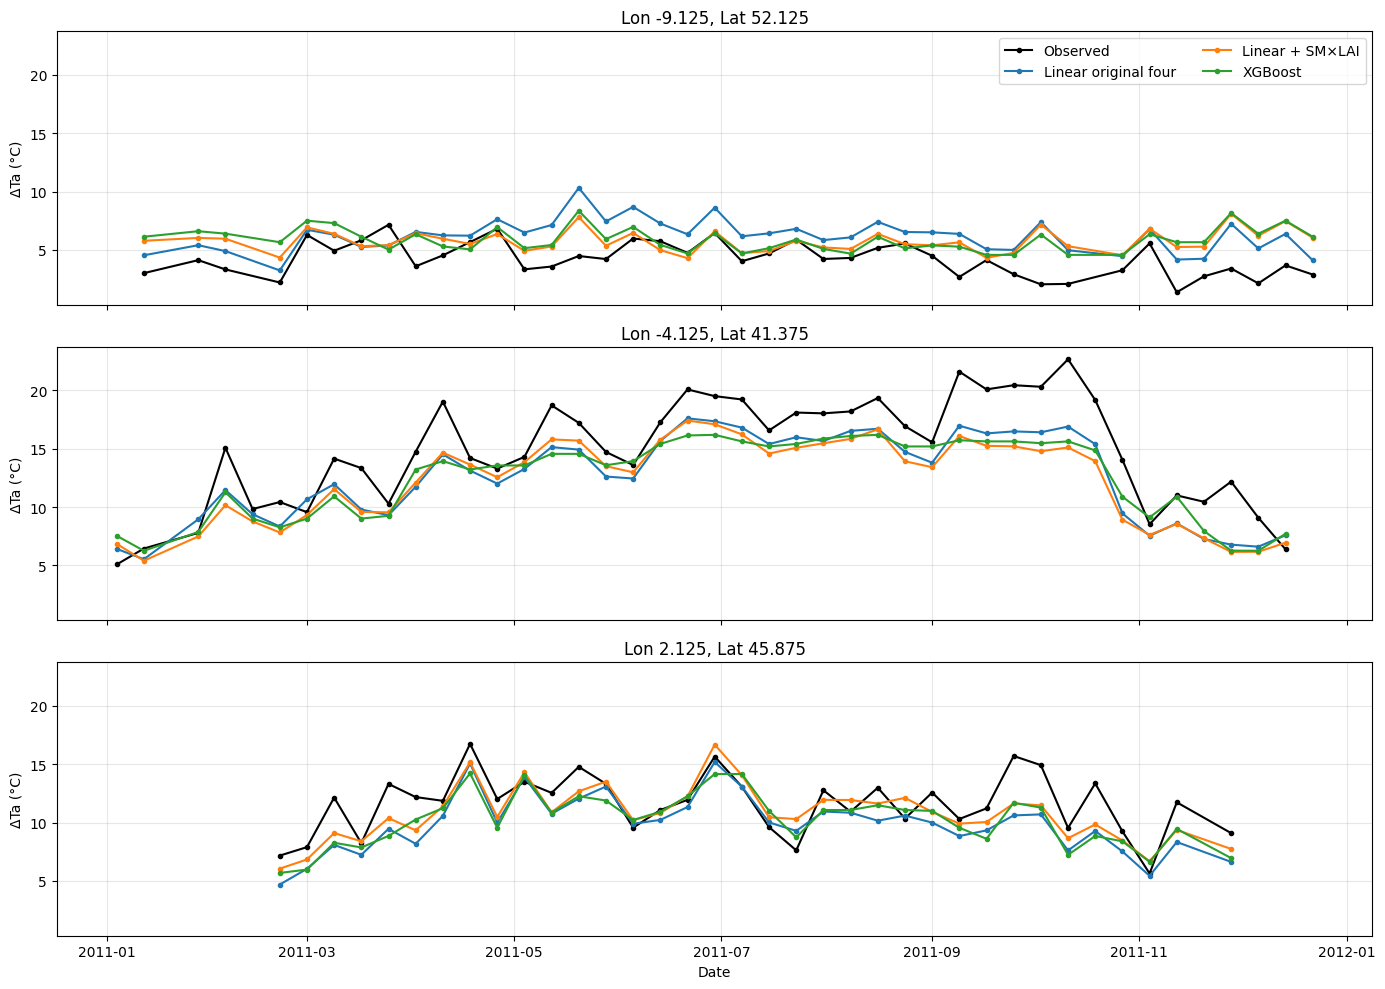

In [5]:
fig, axes = plt.subplots(
    3, 1, figsize=(14, 10), sharex=True, sharey=True
)

colors = {
    "Linear original four": "tab:blue",
    "Linear + SM×LAI": "tab:orange",
    "XGBoost": "tab:green",
}

for ax, ((lon, lat), cell) in zip(
    axes, comparison_predictions.groupby(["lon", "lat"])
):
    cell = cell.sort_values("date")

    ax.plot(
        cell["date"], cell[target],
        "o-", color="black", markersize=3,
        label="Observed",
    )

    for name in model_names:
        ax.plot(
            cell["date"], cell[name],
            "o-", color=colors[name], markersize=3,
            label=name,
        )

    ax.set_title(f"Lon {lon}, Lat {lat}")
    ax.set_ylabel("ΔTa (°C)")
    ax.grid(alpha=0.3)

axes[0].legend(ncol=2)
axes[-1].set_xlabel("Date")

fig.tight_layout()
fig.savefig(
    "xgb_linear_comparison_2011.png",
    dpi=250, bbox_inches="tight",
)
plt.show()

The plot confirms that all three models retain similar systematic errors:
- Top cell: they generally overpredict, especially late in the year.
- Middle cell: all underestimate many high values, particularly September–October. XGBoost does not resolve this.
- Bottom cell: the interaction model captures some peaks better, but all miss several observed increases.
The optional experiment’s conclusion is:

“Adding SM × LAI improved 2010 validation performance and 2011 predictions in two cells, but reduced accuracy in the third. XGBoost also produced mixed improvements. Greater model flexibility did not consistently overcome differences between years and locations.”

This completes our small feature-engineering and XGBoost comparison. Save both notebooks with their outputs. We have enough material for one optional-results slide, with this plot available as a backup figure.